In [181]:
# PyTorch is published as the package named torch, not pytorch
%pip install torch



Note: you may need to restart the kernel to use updated packages.


In [193]:
import torch
import numpy as np
import math
import random
import matplotlib.pyplot as plt
from graphviz import Digraph

In [185]:
def draw_dot(self):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})
    nodes, edges = self.trace()
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label=f"{{ {n.label} | data {n.data:.4f} | grad {n.grad:.4f} }}", shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op, shape='circle')
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

In [194]:
# input
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias
b = Value(6.8813735870195432, label='b')

# forward pass
x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

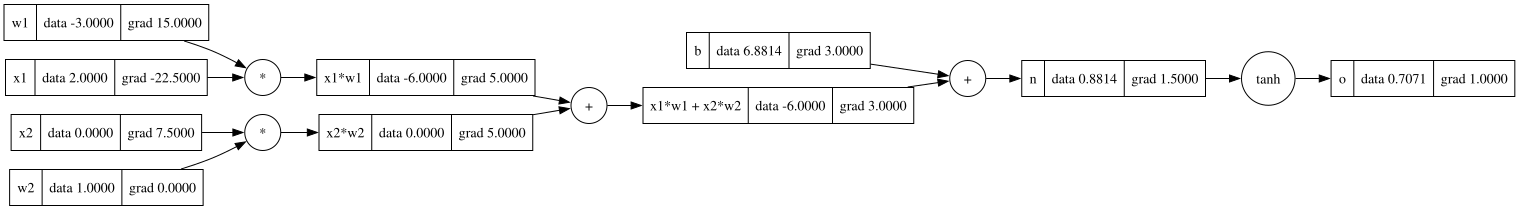

In [201]:
draw_dot(o)

In [200]:
o.backward()

In [202]:
# using PyTorch
import torch
x1 = torch.tensor(2.0, requires_grad=True)
x2 = torch.tensor(0.0, requires_grad=True)
w1 = torch.tensor(-3.0, requires_grad=True)
w2 = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(6.8813735870195432, requires_grad=True)
logit = x1*w1 + x2*w2 + b
o = torch.tanh(logit)
o.backward()
print(o.data.item())

0.7071067094802856


In [203]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))
    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
    def parameters(self):
        return self.w + [self.b]
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
    def __call__(self, x):
        return [n(x) for n in self.neurons]
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [204]:
xs= [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
n = Neuron(3)
for x,y in zip(xs, ys):
    print(x, n(x))
    print(x, y)

[2.0, 3.0, -1.0] Value(data=0.9466946712814595, grad=0.0, label=, _op=tanh)
[2.0, 3.0, -1.0] 1.0
[3.0, -1.0, 0.5] Value(data=0.196491184436523, grad=0.0, label=, _op=tanh)
[3.0, -1.0, 0.5] -1.0
[0.5, 1.0, 1.0] Value(data=0.6493817386133942, grad=0.0, label=, _op=tanh)
[0.5, 1.0, 1.0] -1.0
[1.0, 1.0, -1.0] Value(data=-0.010740089360135752, grad=0.0, label=, _op=tanh)
[1.0, 1.0, -1.0] 1.0


In [207]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((ygt-ypred)**2 for ygt, ypred in zip(ys, ypred))
    print(k, loss.data)
    # backward pass
    for p in n.parameters():
        p.grad = 0.0 # reset gradients
    loss.backward() # accumulate gradients
    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad # learning rate 0.05

0 0.04306506607675058
1 0.04187736086339833
2 0.040751808203718126
3 0.039683710426750146
4 0.038668828334699784
5 0.03770332687151548
6 0.03678372831140936
7 0.035906871783785974
8 0.03506987815876146
9 0.03427011948511884
10 0.03350519230854169
11 0.03277289430879961
12 0.03207120378528032
13 0.03139826159484803
14 0.03075235520757815
15 0.03013190459693764
16 0.02953544972343214
17 0.028961639406174813
18 0.02840922140652597
19 0.02787703357291047
